1. Install Required Libraries

In [5]:
%pip install pandas numpy scikit-learn xgboost matplotlib seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


2. Import Libraries

In [6]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from xgboost import XGBClassifier

import matplotlib.pyplot as plt
import seaborn as sns

3. Load Dataset

In [7]:
dataset_path = "PhD Student Dataset.csv"
df = pd.read_csv(dataset_path)
df.head()

,Cluster,Type,Registration Date,Proposal Review Date,Research Review Date,NOS Date,Final Draft Submission Date,Viva Date
0,Data to Knowledge,Full Time,01/10/2014,1/12/2015,20/5/2018,16/8/2018,6/9/2018,28/5/2019
1,Data to Knowledge,Full Time,01/07/2020,1/7/2021,20/8/2024,21/8/2024,23/8/2024,12/12/2024
2,Data to Knowledge,Full Time,01/10/2021,1/11/2022,20/7/2025,21/7/2025,5/8/2025,2/4/2026
3,Data to Knowledge,Full Time,01/03/2020,1/1/2023,1/2/2024,8/12/2024,11/12/2024,23/4/2025
4,Data to Knowledge,Full Time,01/03/2020,1/12/2022,1/3/2024,10/3/2024,7/6/2024,15/10/2024


4. Convert Date Columns to Datetime

In [8]:
date_columns = [
    "Registration Date",
    "Proposal Review Date",
    "Research Review Date",
    "NOS Date",
    "Final Draft Submission Date",
    "Viva Date"
]

for col in date_columns:
    df[col] = pd.to_datetime(df[col], dayfirst=True, errors='coerce')

5. Convert Dates → Semester Numbers
Semester I = Sept – Feb
Semester II = March – Aug

In [ ]:
def semester_token(date_value):
    month = date_value.month
    year = date_value.year

    if month >= 9:
        return year, 1

    if month <= 2:
        return year - 1, 1

    return year, 2


def get_semester_index(reg_date, target_date):
    if pd.isna(reg_date) or pd.isna(target_date):
        return np.nan

    reg_year, reg_sem = semester_token(reg_date)
    target_year, target_sem = semester_token(target_date)

    reg_index = reg_year * 2 + (reg_sem - 1)
    target_index = target_year * 2 + (target_sem - 1)

    return int(target_index - reg_index + 1)

6. Create Semester-Based Features

In [10]:
df["proposal_sem"] = df.apply(lambda x: get_semester_index(x["Registration Date"], x["Proposal Review Date"]), axis=1)

df["research_sem"] = df.apply(lambda x: get_semester_index(x["Registration Date"], x["Research Review Date"]), axis=1)

df["nos_sem"] = df.apply(lambda x: get_semester_index(x["Registration Date"], x["NOS Date"]), axis=1)

df["final_draft_sem"] = df.apply(lambda x: get_semester_index(x["Registration Date"], x["Final Draft Submission Date"]), axis=1)

df["viva_sem"] = df.apply(lambda x: get_semester_index(x["Registration Date"], x["Viva Date"]), axis=1)

7. Encode Cluster and Type

In [ ]:
cluster_mapping = {
    "Data to Knowledge": 0,
    "Service Computing": 1,
    "Enabling Technologies & Infrastructures": 2,
}

type_mapping = {
    "Full Time": 0,
    "Part Time": 1,
}

df["Cluster"] = df["Cluster"].map(cluster_mapping)
df["Type"] = df["Type"].map(type_mapping)

In [12]:
def calculate_got(row):
    
    duration = row["viva_sem"]
    
    if row["Type"] == 0:  # Full Time
        return 1 if duration <= 10 else 0
    
    else:  # Part Time
        return 1 if duration <= 15 else 0

df["GOT"] = df.apply(calculate_got, axis=1)

In [13]:
features = [
    "Cluster",
    "Type",
    "proposal_sem",
    "research_sem",
    "nos_sem",
    "final_draft_sem"
]

X = df[features]
y = df["GOT"]

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [15]:
model = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    random_state=42
)

model.fit(X_train, y_train)

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes 

In [16]:
y_pred = model.predict(X_test)

In [17]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report")
print(classification_report(y_test, y_pred))

Accuracy: 0.9833333333333333

Classification Report
              precision    recall  f1-score   support

           0       0.93      1.00      0.97        42
           1       1.00      0.98      0.99       138

    accuracy                           0.98       180
   macro avg       0.97      0.99      0.98       180
weighted avg       0.98      0.98      0.98       180



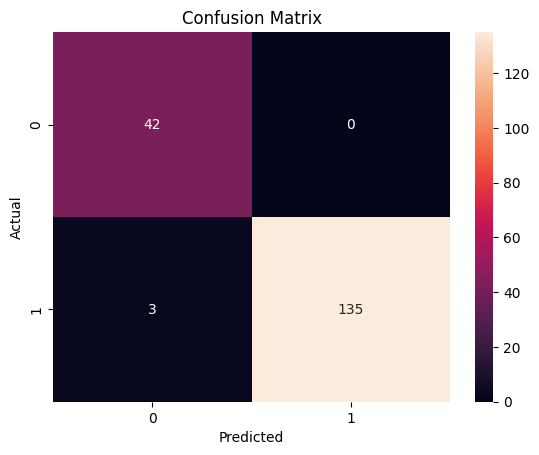

In [18]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

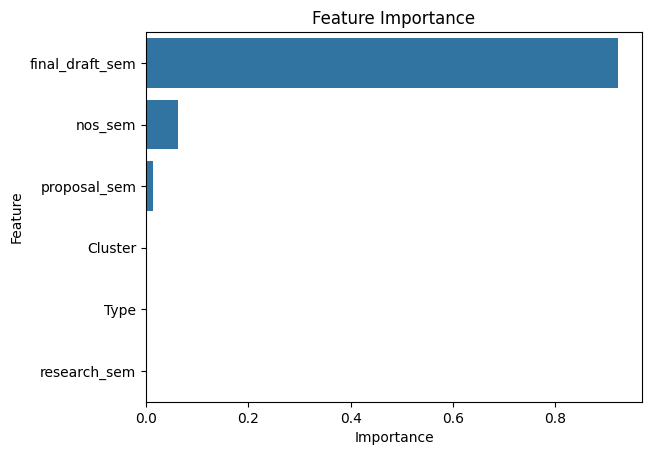

In [19]:
importances = model.feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

sns.barplot(data=feature_importance_df, x="Importance", y="Feature")
plt.title("Feature Importance")
plt.show()

In [20]:
import joblib

joblib.dump(model, "got_prediction_model.pkl")

['got_prediction_model.pkl']

In [21]:
model.predict_proba(X)

array([[0.00183684, 0.99816316],
       [0.00183684, 0.99816316],
       [0.00183684, 0.99816316],
       ...,
       [0.00183898, 0.998161  ],
       [0.00183898, 0.998161  ],
       [0.00183898, 0.998161  ]], shape=(900, 2), dtype=float32)